In [1]:
import os

if os.name == "nt":
    os.environ.setdefault("HADOOP_HOME", r"C:\hadoop")
    os.environ["PATH"] += os.pathsep + os.path.join(os.environ["HADOOP_HOME"], "bin")

In [2]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("transactions-analytics")
    .config(
        "spark.jars.packages",
        "org.apache.hadoop:hadoop-aws:3.3.4,"
        "com.amazonaws:aws-java-sdk-bundle:1.12.262"
    )
    .config("spark.hadoop.fs.s3a.access.key", "minio")
    .config("spark.hadoop.fs.s3a.secret.key", "minio123")
    .config("spark.hadoop.fs.s3a.endpoint", "http://localhost:9000")
    .config("spark.hadoop.fs.s3a.path.style.access", "true")
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem")
    .getOrCreate()
)

In [3]:
df = spark.read.parquet("s3a://warehouse/transactions")
df.printSchema()
df.show(5, truncate=False)

root
 |-- id_transaction: string (nullable = true)
 |-- type_transaction: string (nullable = true)
 |-- montant: double (nullable = true)
 |-- devise: string (nullable = true)
 |-- date: string (nullable = true)
 |-- lieu: string (nullable = true)
 |-- moyen_paiement: string (nullable = true)
 |-- details: struct (nullable = true)
 |    |-- produit: string (nullable = true)
 |    |-- quantite: integer (nullable = true)
 |    |-- prix_unitaire: double (nullable = true)
 |-- utilisateur: struct (nullable = true)
 |    |-- id_utilisateur: string (nullable = true)
 |    |-- nom: string (nullable = true)
 |    |-- adresse: string (nullable = true)
 |    |-- email: string (nullable = true)
 |-- montant_eur: double (nullable = true)
 |-- timezone: string (nullable = false)
 |-- date_ts: timestamp (nullable = true)
 |-- date_only: date (nullable = true)

+------------------------------------+----------------+-------+------+--------------------------+--------------------------------+-----------

In [4]:
df.select("date_only").distinct().show()

+----------+
| date_only|
+----------+
|2025-12-27|
+----------+



In [5]:
df.groupBy("moyen_paiement") \
  .sum("montant_eur") \
  .orderBy("sum(montant_eur)", ascending=False) \
  .show()

+-----------------+------------------+
|   moyen_paiement|  sum(montant_eur)|
+-----------------+------------------+
|  carte_de_credit| 487265.9755999998|
|          especes| 485964.2859999995|
|virement_bancaire|469331.94640000036|
+-----------------+------------------+



In [6]:
df.groupBy("type_transaction").count().show()

+----------------+-----+
|type_transaction|count|
+----------------+-----+
|           achat| 1033|
|   remboursement| 1070|
|       transfert| 1060|
+----------------+-----+



In [7]:
df.groupBy("date_only") \
  .sum("montant_eur") \
  .orderBy("date_only") \
  .show()

+----------+------------------+
| date_only|  sum(montant_eur)|
+----------+------------------+
|2025-12-27|1442562.2080000031|
+----------+------------------+



In [8]:
flat = (
    df
    .withColumn("produit", df.details.produit)
    .withColumn("quantite", df.details.quantite)
    .withColumn("prix_unitaire", df.details.prix_unitaire)
    .withColumn("user_id", df.utilisateur.id_utilisateur)
    .withColumn("user_nom", df.utilisateur.nom)
    .drop("details", "utilisateur")
)

flat.printSchema()
flat.show(5, truncate=False)

root
 |-- id_transaction: string (nullable = true)
 |-- type_transaction: string (nullable = true)
 |-- montant: double (nullable = true)
 |-- devise: string (nullable = true)
 |-- date: string (nullable = true)
 |-- lieu: string (nullable = true)
 |-- moyen_paiement: string (nullable = true)
 |-- montant_eur: double (nullable = true)
 |-- timezone: string (nullable = false)
 |-- date_ts: timestamp (nullable = true)
 |-- date_only: date (nullable = true)
 |-- produit: string (nullable = true)
 |-- quantite: integer (nullable = true)
 |-- prix_unitaire: double (nullable = true)
 |-- user_id: string (nullable = true)
 |-- user_nom: string (nullable = true)

+------------------------------------+----------------+-------+------+--------------------------+--------------------------------+--------------+------------------+------------+--------------------------+----------+---------+--------+-------------+-------+--------------+
|id_transaction                      |type_transaction|montant|d

In [9]:
pdf = (
    flat.groupBy("moyen_paiement")
    .sum("montant_eur")
    .orderBy("sum(montant_eur)", ascending=False)
    .toPandas()
)

pdf

,moyen_paiement,sum(montant_eur)
0,carte_de_credit,487265.9756
1,especes,485964.2860
2,virement_bancaire,469331.9464


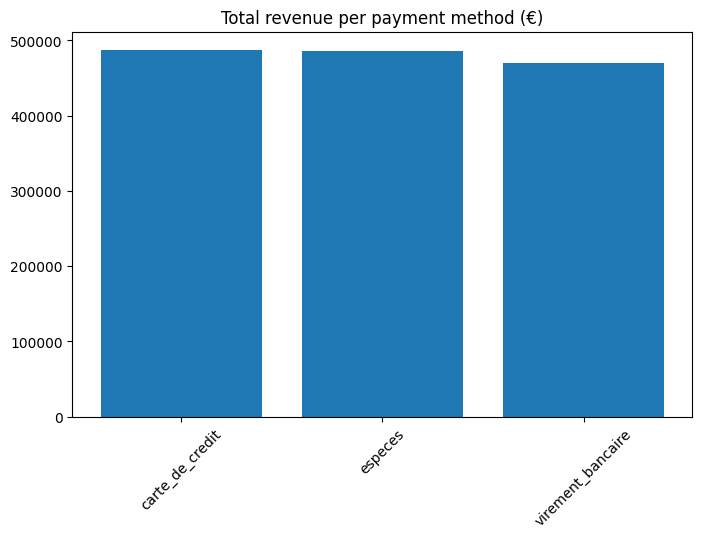

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(pdf["moyen_paiement"], pdf["sum(montant_eur)"])
plt.xticks(rotation=45)
plt.title("Total revenue per payment method (€)")
plt.show()